<a href="https://colab.research.google.com/github/nattaponm/Teach_Pysteps_KKN_summerStorm/blob/main/notebooks/04_deterministic_nowcast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 4: Deterministic nowcasting — เตือนหนองบัวลำภูได้ล่วงหน้ากี่นาที?
### Persistence vs extrapolation vs S-PROG vs ANVIL, verification by storm phase and GeoTIFF export

⏱️ เวลาเรียนโดยประมาณ **75–90 นาที** | ต้องผ่าน: Notebook 1–3

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **สร้าง nowcast 4 วิธี** ด้วย pysteps: Eulerian persistence, extrapolation, S-PROG และ ANVIL
2. **ประเมินคุณภาพ (verification)** ด้วย CSI, POD, FAR และ FSS
3. **อธิบายว่าทำไมความแม่นยำขึ้นกับช่วงชีวิตของพายุ** (ก่อตัว / สูงสุด / รวมตัว)
4. **คำนวณ "เวลาเตือนล่วงหน้า" (warning lead time)** ณ จุดที่เกิดความเสียหายจริง
5. **ส่งออก nowcast เป็น GeoTIFF** เพื่อใช้ใน QGIS

## 📖 1. แนวคิดและสมการ

### 1.1 วิธี nowcast ที่เปรียบเทียบ
| วิธี | แนวคิด | จุดเด่น / ข้อจำกัด |
|---|---|---|
| **Eulerian persistence** | ใช้ภาพล่าสุด ไม่เลื่อนเลย | ค่าอ้างอิงที่วิธีอื่นต้องชนะให้ได้ |
| **Extrapolation** | เลื่อนภาพล่าสุดตาม motion field (Lagrangian persistence) | ไม่เปลี่ยนความแรง ไม่มีเซลล์ใหม่ |
| **S-PROG** | แยกภาพเป็นหลายสเกล (cascade) แต่ละสเกลลดลงตามแบบจำลอง AR(2) | สเกลเล็ก (เซลล์) "จางหาย" เร็ว → ภาพเรียบลงตาม lead time |
| **ANVIL** | AR แบบเปลี่ยนตามตำแหน่ง ใช้ได้กับการ **เติบโต/สลาย** | ออกแบบมาสำหรับพายุพาความร้อน |

**S-PROG:** แต่ละระดับ cascade $j$ พยากรณ์ด้วย
$$ \Psi_j(t+1) = \phi_{j,1}\,\Psi_j(t) + \phi_{j,2}\,\Psi_j(t-1) $$
สเกลเล็กมีสหสัมพันธ์ต่ำ ($\phi$ เล็ก) จึงหายเร็ว — เหมาะกับข้อมูลทุก 15 นาทีที่เซลล์เปลี่ยนเร็ว

### 1.2 Verification แบบ contingency table (ที่ threshold หนึ่ง)
| | สังเกต: เกิด | สังเกต: ไม่เกิด |
|---|---|---|
| **พยากรณ์: เกิด** | Hits (H) | False alarms (F) |
| **พยากรณ์: ไม่เกิด** | Misses (M) | — |

$$ \mathrm{POD}=\frac{H}{H+M},\qquad \mathrm{FAR}=\frac{F}{H+F},\qquad \mathrm{CSI}=\frac{H}{H+M+F} $$

### 1.3 Fractions Skill Score (FSS)
พายุเซลล์เล็กพยากรณ์ "ตรง pixel" ได้ยาก FSS จึงเทียบ **สัดส่วนพื้นที่ฝน** ในหน้าต่างขนาด $n$
$$ \mathrm{FSS}_n = 1 - \frac{\sum (P_f - P_o)^2}{\sum P_f^2 + \sum P_o^2} $$
nowcast "มีประโยชน์" เมื่อ $\mathrm{FSS} \ge 0.5 + f_o/2$ ($f_o$ = สัดส่วนพื้นที่ฝนที่สังเกตได้)

### 1.4 เวลาเตือนล่วงหน้า (warning lead time)
สำหรับจุดหนึ่ง: ย้อนเวลาออก nowcast ทีละ 15 นาที แล้วดูว่า **nowcast รอบแรกสุด** ที่ทำนายฝนหนักถึงจุดนั้น **ตรงเวลา** คือรอบใด
$$ \text{lead time} = t_{\mathrm{event}} - t_{\mathrm{issue,\,earliest\ hit}} $$

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Pysteps_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 cartopy netCDF4 geopandas cmweather rasterio
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "kkn_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.data_io import load_pcappi, time_index, save_geotiff
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 686.9/686.9 kB 11.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 87.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 94.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.3/47.3 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 51.9 MB/s eta 0:00:00
✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Pysteps_KKN_summerStorm/data


In [2]:
from pysteps import motion, nowcasts
from pysteps.utils import transformation
from pysteps.verification.spatialscores import fss
import contextlib, io

Z, meta = load_pcappi(DATA)
ts = meta["timestamps"]
DT = meta["accutime"]
reports = kt.load_reports(DATA, meta)
date0 = ts[0].replace(hour=0, minute=0)

BOX = kt.box_around(meta, 102.4, 17.3, 140)              # พื้นที่ศึกษา 280 × 280 km (เหมือน NB3)
Zc, mc = kt.crop(Z, meta, BOX)
RAIN = kt.dbz_to_rainrate(Zc, 200, 1.6, hail_cap=55)     # mm/h (Marshall–Palmer + hail cap; NB2)
VALID = mc["coverage"] & (np.hypot(*np.meshgrid(mc["x"], mc["y"])) <= 160e3)   # ใช้ verify ภายใน 160 km
meta_r = dict(mc, unit="mm/h", transform=None, threshold=0.1, zerovalue=0.0)
oflow = motion.get_method("LK")
N_LEAD = 8                                               # +15 ถึง +120 นาที
print(f"พื้นที่ {RAIN.shape[1]}×{RAIN.shape[2]} km | verification ภายใน 160 km: {VALID.sum()} pixel")

Pysteps configuration file found at: /usr/local/lib/python3.13/dist-packages/pysteps/pystepsrc

พื้นที่ 280×280 km | verification ภายใน 160 km: 46948 pixel


## 💻 3. ฟังก์ชันสร้าง nowcast สำหรับเวลาออก (issue time) ใด ๆ

In [3]:
METHODS = ["Persistence", "Extrapolation", "S-PROG", "ANVIL"]


def make_nowcast(i0, method, n=N_LEAD, verbose=False):
    """nowcast อัตราฝน (mm/h) n ช่วงเวลา จากข้อมูลถึงเวลา index i0"""
    if not verbose:                                     # ปิดข้อความยาว ๆ ของ pysteps
        with contextlib.redirect_stdout(io.StringIO()):
            return make_nowcast(i0, method, n, verbose=True)
    R_in = np.nan_to_num(RAIN[i0 - 3:i0 + 1], nan=0.0)                  # 4 ภาพล่าสุด
    dbr, md = transformation.dB_transform(R_in, meta_r, threshold=0.1, zerovalue=-15.0)
    V = oflow(dbr[-3:], verbose=False)
    if method == "Persistence":
        F = np.repeat(R_in[-1][None], n, axis=0)
    elif method == "Extrapolation":
        F = nowcasts.get_method("extrapolation")(dbr[-1], V, n)
        F = transformation.dB_transform(F, md, inverse=True)[0]
    elif method == "S-PROG":
        F = nowcasts.get_method("sprog")(dbr[-3:], V, n, precip_thr=md["threshold"], n_cascade_levels=6,
                                         ar_order=2)
        F = transformation.dB_transform(F, md, inverse=True)[0]
    elif method == "ANVIL":
        F = nowcasts.get_method("anvil")(R_in, V, n, ar_window_radius=25, ar_order=2)
    F = np.where(np.isfinite(F) & (F >= 0.1), F, 0.0)
    F[:, ~mc["coverage"]] = np.nan
    return F, V


PHASES = {"Growth (06:30)": "06:30", "Peak (09:00)": "09:00", "Upscale growth (11:30)": "11:30"}
NOW = {}
for label, hh in PHASES.items():
    i0 = time_index(meta, hh)
    NOW[label] = {m: make_nowcast(i0, m)[0] for m in METHODS}
    print(f"✓ {label}: {', '.join(METHODS)}")

✓ Growth (06:30): Persistence, Extrapolation, S-PROG, ANVIL
✓ Peak (09:00): Persistence, Extrapolation, S-PROG, ANVIL
✓ Upscale growth (11:30): Persistence, Extrapolation, S-PROG, ANVIL


### แผนที่: nowcast ออก 09:00 UTC (16:00 น.) เทียบค่าสังเกต
เส้นดำ = ขอบฝน 10 mm/h ที่สังเกตจริง

บันทึกรูปแล้ว: figures/nb4_nowcast_maps_0900.png, figures/nb4_nowcast_maps_0900.pdf


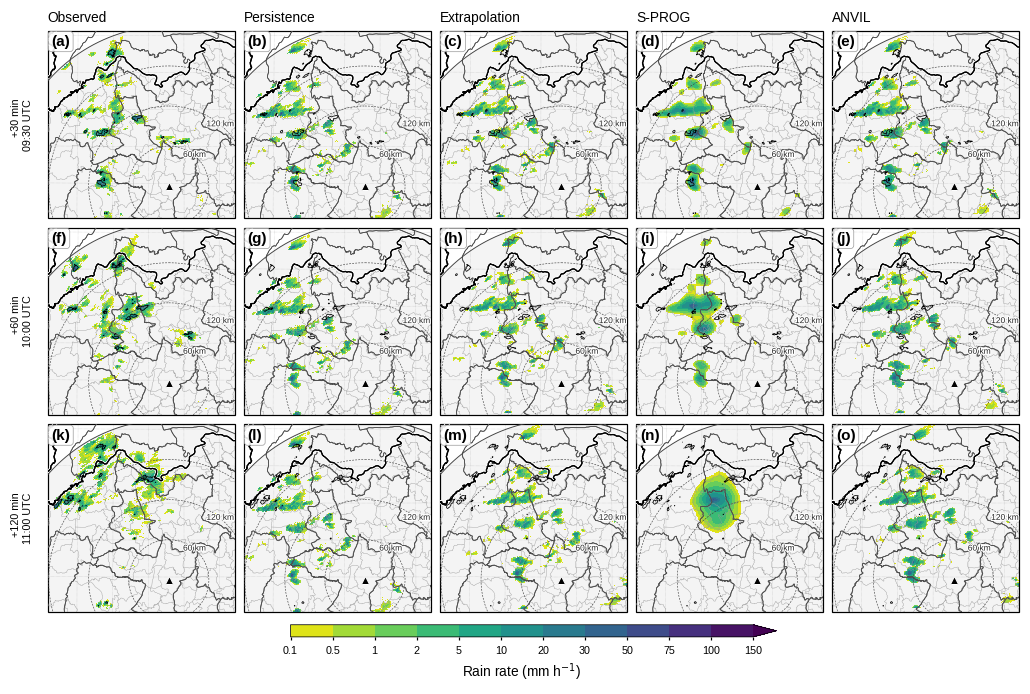

In [4]:
i0 = time_index(meta, "09:00")
leads = [2, 4, 8]                                       # +30, +60, +120 นาที
fig, axs = mp.map_panels(len(leads), 5, mc, panel_width=1.85)
for r_, L in enumerate(leads):
    obs = RAIN[i0 + L]
    for c_, m in enumerate(["Observed"] + METHODS):
        ax = axs[r_ * 5 + c_]
        field = obs if m == "Observed" else NOW["Peak (09:00)"][m][L - 1]
        im = mp.radar_map(ax, field, mc, units="mm/h", scalebar=False, north=False,
                          title=(m if r_ == 0 else None), points=False,
                          gridline_labels=())
        mp.obs_contour(ax, obs, mc, level=10, linewidth=0.5)
        if c_ == 0:
            ax.text(-0.08, 0.5, f"+{L*DT:.0f} min\n{mp.tlabel(ts[i0 + L], local=False)}", transform=ax.transAxes,
                    rotation=90, ha="right", va="center", fontsize=7)
mp.panel_labels(axs)
mp.add_colorbar(fig, im, axs, shrink=0.5)
mp.save_figure(fig, "nb4_nowcast_maps_0900")
plt.show()

สังเกต: **S-PROG ทำให้ภาพเรียบ** (เซลล์เล็กจางหาย) ตาม lead time, **ANVIL** ยังคงรายละเอียดแต่ปรับความแรงได้, **extrapolation** เลื่อนภาพเดิมไปทั้งก้อน

### ทำไม S-PROG จึงทำให้ภาพเรียบ? ดูค่าสหสัมพันธ์ของแต่ละสเกล
ระดับ 1 = สเกลใหญ่ (ทั้งระบบ), ระดับ 6 = สเกลเล็ก (ไม่กี่ km) — **Lag-1** คือสหสัมพันธ์ระหว่างภาพที่ห่างกัน 15 นาที

In [5]:
buf = io.StringIO()
with contextlib.redirect_stdout(buf):
    make_nowcast(time_index(meta, "09:00"), "S-PROG", n=1, verbose=True)
print("\n".join(l for l in buf.getvalue().splitlines() if l.startswith("|"))[:900])

| Level |     Lag-1     |     Lag-2     |
| 1     | 0.939408      | 0.848275      |
| 2     | 0.748474      | 0.354177      |
| 3     | 0.745224      | 0.423416      |
| 4     | 0.440943      | 0.086413      |
| 5     | 0.108211      | 0.027188      |
| 6     | -0.005142     | 0.002833      |
| Level |    Phi-1     |    Phi-2     |    Phi-0     |
| 1     | 1.212905     | -0.291138    | 0.327951     |
| 2     | 0.900060     | -0.202527    | 0.649422     |
| 3     | 0.894189     | -0.199893    | 0.653357     |
| 4     | 0.464754     | -0.053999    | 0.896225     |
| 5     | 0.106516     | 0.015662     | 0.994006     |
| 6     | -0.005128    | 0.002807     | 0.999983     |


## 📏 4. Verification: CSI ตาม lead time ใน 3 ช่วงของพายุ (threshold 1 mm/h)

บันทึกรูปแล้ว: figures/nb4_csi_by_phase.png, figures/nb4_csi_by_phase.pdf


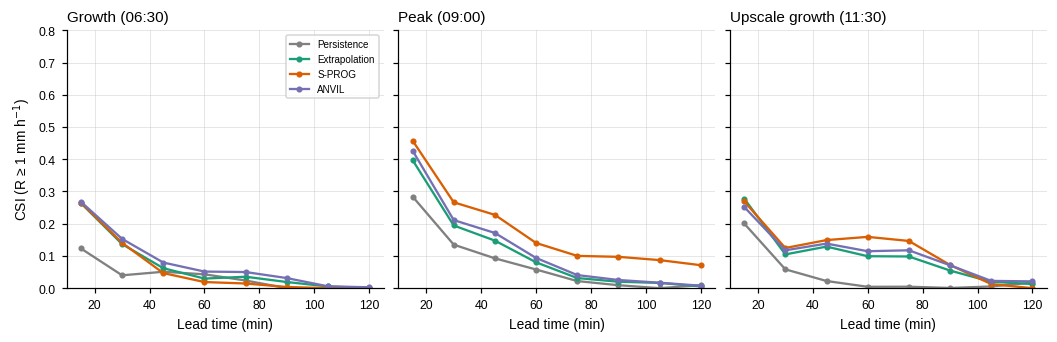

In [6]:
def csi_curve(F, i0, thr):
    return np.array([kt.contingency(F[L - 1], RAIN[i0 + L], thr, VALID)["CSI"] for L in range(1, N_LEAD + 1)])


lead_min = np.arange(1, N_LEAD + 1) * DT
colors = {"Persistence": "0.5", "Extrapolation": "#1b9e77", "S-PROG": "#d95f02", "ANVIL": "#7570b3"}
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3.0), sharey=True, layout="constrained")
for ax, (label, hh) in zip(axs, PHASES.items()):
    i0 = time_index(meta, hh)
    for m in METHODS:
        ax.plot(lead_min, csi_curve(NOW[label][m], i0, 1.0), "o-", ms=3, color=colors[m], label=m)
    mp.skill_axes(ax, ylabel="CSI (R ≥ 1 mm h$^{-1}$)" if ax is axs[0] else "", ylim=(0, 0.8), title=label)
axs[0].legend(fontsize=6.5)
mp.save_figure(fig, "nb4_csi_by_phase")
plt.show()

## 💾 5. ส่งออก nowcast เป็น GeoTIFF (เปิดใน QGIS ได้ทันที)
ระบบพิกัด = Azimuthal Equidistant ที่มีเรดาร์เป็นศูนย์กลาง (บันทึกไว้ในไฟล์แล้ว QGIS จะ reproject ให้อัตโนมัติ)

In [7]:
os.makedirs("output", exist_ok=True)
F_exp = NOW["Peak (09:00)"]["S-PROG"]
tif = save_geotiff("output/KKN_nowcast_SPROG_20240503_0900.tif", F_exp, mc,
                   band_names=[f"+{(k + 1) * DT:.0f} min (mm/h)" for k in range(N_LEAD)])
print("บันทึก:", tif, f"({os.path.getsize(tif)/1e6:.2f} MB, {N_LEAD} bands)")

บันทึก: output/KKN_nowcast_SPROG_20240503_0900.tif (0.19 MB, 8 bands)


---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 4.1: ฝนปานกลาง–หนัก — ช่วงไหนพยากรณ์ง่ายที่สุด?
คำนวณ **CSI, POD และ FAR ที่ threshold 5 mm/h** (≈ 33 dBZ) และ **10 mm/h** (≈ 39 dBZ) ที่ lead time **+30 และ +60 นาที** ของทุกวิธี ทุกช่วงพายุ แล้วสร้างตาราง

**คำถาม:** ช่วงใดพยากรณ์ได้ดีที่สุด และวิธีใดดีที่สุดในช่วงนั้น? ทำไม CSI ที่ 10 mm/h จึงเกือบเป็นศูนย์แม้ที่ +30 นาที? (คิดถึงขนาดของแกนฝนหนักเทียบกับระยะที่พายุเคลื่อนใน 15 นาที)

<details>
<summary><b>💡 คำใบ้ (คลิกเพื่อเปิด)</b></summary>

- วน `for label, hh in PHASES.items():`, `for m in METHODS:`, `for L in [2, 4]:`
- `kt.contingency(NOW[label][m][L - 1], RAIN[i0 + L], 10, VALID)` คืน dict ที่มี `"CSI"`, `"POD"`, `"FAR"`
- `pd.DataFrame(rows).pivot_table(index=["phase", "lead"], columns="method", values="CSI")`

</details>

In [8]:
# ✍️ แบบฝึกหัด 4.1 — เขียนโค้ดของคุณที่นี่ (ลบ # หน้าบรรทัดแล้วเติมส่วนที่เป็น ...)
# rows = []
# for label, hh in PHASES.items():
#     i0 = time_index(meta, hh)
#     for m in METHODS:
#         for L in [2, 4]:
#             for thr in [5, 10]:
#                 s = kt.contingency(...)
#             ...

In [9]:
#@title ✅ เฉลยแบบฝึกหัด 4.1 (ลองทำเองก่อน! ดับเบิลคลิกเพื่อดูโค้ด แล้วกด ▶ เพื่อรัน)
rows = []
for label, hh in PHASES.items():
    i0 = time_index(meta, hh)
    for m in METHODS:
        for L in [2, 4]:
            for thr in [5, 10]:
                s = kt.contingency(NOW[label][m][L - 1], RAIN[i0 + L], thr, VALID)
                rows.append({"phase": label, "lead": f"+{L*DT:.0f} min", "thr": thr, "method": m, **s})
v41 = pd.DataFrame(rows)
for thr in [5, 10]:
    print(f"CSI (R ≥ {thr} mm/h)")
    print(v41[v41["thr"] == thr].pivot_table(index=["phase", "lead"], columns="method", values="CSI", sort=False).round(2), "\n")
print("POD ที่ +30 นาที, R ≥ 5 mm/h")
print(v41[(v41["lead"] == "+30 min") & (v41["thr"] == 5)].pivot_table(index="phase", columns="method", values="POD", sort=False).round(2))
best = v41[(v41["thr"] == 5) & (v41["lead"] == "+30 min")].sort_values("CSI", ascending=False).iloc[0]
print(f"\n→ ดีที่สุดที่ +30 นาที (5 mm/h): {best['method']} ช่วง {best['phase']} (CSI = {best['CSI']:.2f})"
      "\n  แกนฝนหนักกว้างเพียงไม่กี่ km แต่พายุเคลื่อนที่ 6–10 km ใน 15 นาที และเปลี่ยนรูปตลอด → การพยากรณ์ 'ตรง pixel' แทบเป็นไปไม่ได้")

CSI (R ≥ 5 mm/h)
method                          Persistence  Extrapolation  S-PROG  ANVIL
phase                  lead                                              
Growth (06:30)         +30 min         0.01           0.05    0.04   0.08
                       +60 min         0.01           0.02    0.00   0.03
Peak (09:00)           +30 min         0.07           0.11    0.17   0.13
                       +60 min         0.02           0.00    0.01   0.01
Upscale growth (11:30) +30 min         0.01           0.02    0.00   0.02
                       +60 min         0.00           0.03    0.00   0.01 

CSI (R ≥ 10 mm/h)
method                          Persistence  Extrapolation  S-PROG  ANVIL
phase                  lead                                              
Growth (06:30)         +30 min         0.01           0.04    0.00   0.06
                       +60 min         0.00           0.00    0.00   0.00
Peak (09:00)           +30 min         0.04           0.06    0.15   0.08
 

### 🧪 แบบฝึกหัด 4.2: nowcast มีประโยชน์ที่สเกลใด? (FSS)
ใช้ nowcast ออก 09:00 UTC ทั้ง 4 วิธี คำนวณ **FSS ที่ threshold 10 mm/h** ที่หน้าต่าง 1, 5, 10, 20, 40 km สำหรับ lead time **+30 และ +60 นาที** พล็อต FSS กับขนาดหน้าต่าง พร้อมเส้น "useful" $0.5 + f_o/2$

**คำถาม:** ที่ +60 นาที nowcast มีประโยชน์ตั้งแต่สเกลกี่ km? ผลนี้บอกอะไรเกี่ยวกับการเตือนภัย "ระดับอำเภอ" เทียบกับ "ระดับตำบล"?

<details>
<summary><b>💡 คำใบ้</b></summary>

- FSS ต้องไม่มี NaN: `f = np.where(VALID, np.nan_to_num(F[L - 1]), 0)` และทำเช่นเดียวกันกับค่าสังเกต
- `fss(f, o, 10.0, scale)`
- $f_o$ = `np.mean(o[VALID] >= 10)`

</details>

In [10]:
# ✍️ แบบฝึกหัด 4.2 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb4_ex42_fss.png, figures/nb4_ex42_fss.pdf


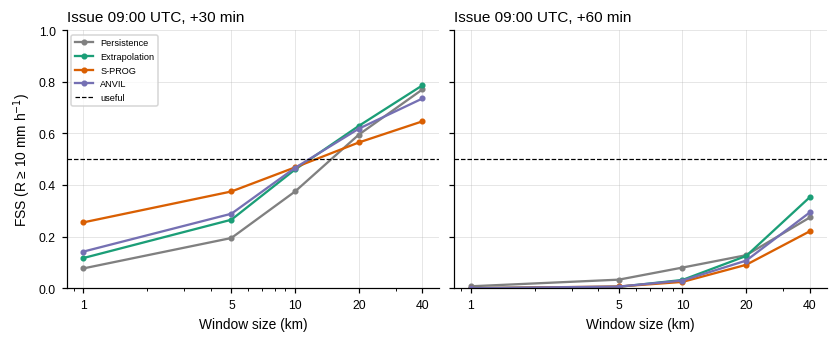

In [11]:
#@title ✅ เฉลยแบบฝึกหัด 4.2
i0 = time_index(meta, "09:00")
scales = [1, 5, 10, 20, 40]
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3), sharey=True, layout="constrained")
for ax, L in zip(axs, [2, 4]):
    o = np.where(VALID, np.nan_to_num(RAIN[i0 + L]), 0)
    fo = np.mean(o[VALID] >= 10)
    for m in METHODS:
        f = np.where(VALID, np.nan_to_num(NOW["Peak (09:00)"][m][L - 1]), 0)
        ax.plot(scales, [fss(f, o, 10.0, s) for s in scales], "o-", ms=3, color=colors[m], label=m)
    ax.axhline(0.5 + fo / 2, color="k", ls="--", lw=0.8, label="useful")
    ax.set_xscale("log")
    ax.set_xticks(scales)
    ax.set_xticklabels(scales)
    mp.skill_axes(ax, xlabel="Window size (km)", ylabel="FSS (R ≥ 10 mm h$^{-1}$)" if L == 2 else "",
                  ylim=(0, 1), title=f"Issue 09:00 UTC, +{L*DT:.0f} min")
axs[0].legend(fontsize=6)
mp.save_figure(fig, "nb4_ex42_fss")
plt.show()

### 🧪 แบบฝึกหัด 4.3: เตือนภัยที่นากลางและศรีเชียงใหม่ได้ล่วงหน้ากี่นาที?
1. หา **เวลาแรกที่ฝน ≥ 20 mm/h (≈ 45 dBZ)** ภายในรัศมี 5 km ของจุด `Na Klang` (และ `Si Chiang Mai`) จากค่าสังเกต = $t_{event}$
2. ออก nowcast ด้วย **Extrapolation** และ **S-PROG** ทุก 15 นาที ตั้งแต่ $t_{event}$ − 120 นาที ถึง $t_{event}$ − 15 นาที
3. nowcast รอบใด "ทำนายถูก" = ค่าสูงสุดภายใน **10 km** รอบจุด ที่เวลา $t_{event}$ ≥ 20 mm/h
4. warning lead time = $t_{event}$ − เวลาออก nowcast รอบแรกสุดที่ทำนายถูก (ไม่นับรอบที่พลาดก่อนหน้า)

**คำถาม:** ได้เวลาเตือนกี่นาที? เพียงพอสำหรับให้ประชาชนเก็บของ/หลบภัยหรือไม่? ทำไม S-PROG จึงอาจ "พลาด" ทั้งที่ CSI ดีกว่า? และที่ศรีเชียงใหม่เกิดอะไรขึ้น?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `s = kt.point_series(RAIN, mc, r["lon"], r["lat"], 5)` แล้ว `i_ev = np.where(s >= 20)[0]` (เลือกค่าแรกหลัง 05:00 UTC)
- สำหรับ issue index `i0` lead `L = i_ev - i0`: `F, _ = make_nowcast(i0, method, n=L)` แล้ว `kt.point_series(F[L - 1][None], mc, lon, lat, 10)[0]`
- วนจาก `i0 = i_ev - 1` ถอยหลังไปเรื่อย ๆ จนกว่าจะพลาด

</details>

In [12]:
# ✍️ แบบฝึกหัด 4.3 — เขียนโค้ดของคุณที่นี่

In [13]:
#@title ✅ เฉลยแบบฝึกหัด 4.3
THR = 20.0
i_start = time_index(meta, "05:00")
rows = []
for name in ["Na Klang", "Si Chiang Mai"]:
    r = kt.site(reports, name)
    s = kt.point_series(RAIN, mc, r["lon"], r["lat"], 5)
    cand = [i for i in np.where(s >= THR)[0] if i >= i_start]
    if not cand:
        print(f"{name}: ไม่มีฝน ≥ {THR} mm/h ในค่าสังเกต")
        continue
    i_ev = cand[0]
    for method in ["Extrapolation", "S-PROG"]:
        hits = []
        for L in range(1, 9):
            i0 = i_ev - L
            if not meta["available"][i0 - 3:i0 + 1].all():
                break
            F, _ = make_nowcast(i0, method, n=L)
            hits.append(kt.point_series(F[L - 1][None], mc, r["lon"], r["lat"], 10)[0] >= THR)
        lead = 0
        for k, h in enumerate(hits, start=1):        # นับรอบที่ถูกต่อเนื่องจากใกล้ที่สุดย้อนไป
            if h:
                lead = k * DT
            else:
                break
        rows.append({"site": name, "event_time": mp.tlabel(ts[i_ev]), "method": method,
                     "hits_by_lead(15→120 min)": "".join("✓" if h else "✗" for h in hits),
                     "warning_lead_min": lead})
lt = pd.DataFrame(rows)
print(lt.to_string(index=False))
print("\n✓/✗ เรียงจาก lead +15 นาที (ออกก่อนเหตุ 15 นาที) ไปจนถึง +120 นาที")
print("→ S-PROG ทำให้ภาพเรียบ ค่าสูงสุดจึงต่ำกว่า 20 mm/h แม้ตำแหน่งถูก (ได้ CSI ดีแต่ 'ไม่เตือน' ฝนหนัก)"
      "\n  ที่ศรีเชียงใหม่ (~160 km) เรดาร์วัดได้ไม่ถึง 20 mm/h เลย จึงกำหนด 'เหตุการณ์' จากเรดาร์ไม่ได้ ทั้งที่มีความเสียหายจริง")

Si Chiang Mai: ไม่มีฝน ≥ 20.0 mm/h ในค่าสังเกต
    site           event_time        method hits_by_lead(15→120 min)  warning_lead_min
Na Klang 09:15 UTC (16:15 LT) Extrapolation                 ✓✗✗✗✗✗✗✗              15.0
Na Klang 09:15 UTC (16:15 LT)        S-PROG                 ✗✗✗✗✗✗✗✗               0.0

✓/✗ เรียงจาก lead +15 นาที (ออกก่อนเหตุ 15 นาที) ไปจนถึง +120 นาที
→ S-PROG ทำให้ภาพเรียบ ค่าสูงสุดจึงต่ำกว่า 20 mm/h แม้ตำแหน่งถูก (ได้ CSI ดีแต่ 'ไม่เตือน' ฝนหนัก)
  ที่ศรีเชียงใหม่ (~160 km) เรดาร์วัดได้ไม่ถึง 20 mm/h เลย จึงกำหนด 'เหตุการณ์' จากเรดาร์ไม่ได้ ทั้งที่มีความเสียหายจริง


---
## 📝 สรุป
- **ทุกวิธีชนะ persistence** แต่ CSI (≥ 1 mm/h) ลดจาก ~0.3–0.45 ที่ +15 นาที เหลือ < 0.15 ที่ +60 นาที — พายุเซลล์อายุสั้นและข้อมูลทุก 15 นาที
- **ช่วงก่อตัวพยากรณ์ยากที่สุด** (เซลล์ใหม่เกิดในที่ที่ยังไม่มีฝน) และ **S-PROG ดีที่สุดช่วงพายุสูงสุด** เพราะลดความผิดพลาดด้วยการทำให้ภาพเรียบ
- **FSS:** ที่ +30 นาที nowcast มีประโยชน์เมื่อดูที่สเกล ≳ 12–15 km ขึ้นไป แต่ที่ +60 นาทีไม่มีประโยชน์แม้ที่ 40 km → เหมาะกับการเตือนระดับอำเภอ ไม่ใช่ระดับตำบล
- **เวลาเตือนล่วงหน้าที่นากลางเพียง ~15 นาที** (extrapolation) และ S-PROG "ไม่เตือน" เพราะภาพเรียบจนค่าสูงสุดต่ำกว่าเกณฑ์ — ข้อจำกัดสำคัญของการเตือนพายุฤดูร้อนด้วย nowcast อย่างเดียว

### ❓ คำถามชวนคิด
1. ถ้ากรมอุตุฯ ต้องการเตือนภัยพายุฤดูร้อนล่วงหน้า 1–2 ชั่วโมง ควรใช้ข้อมูลอะไรเพิ่มนอกจาก nowcast จากเรดาร์? (คิดถึง CAPE/DCAPE, ดาวเทียม, NWP)
2. CSI ที่ 1 mm/h กับ 10 mm/h ต่างกันมาก — ผู้ใช้กลุ่มใดสนใจ threshold ใด (เกษตรกร, ปภ., การไฟฟ้า)?
3. ทำไมการ verify เฉพาะในรัศมี 160 km จึงสำคัญ?

**🚀 ต่อยอด:** ลองใช้ `nowcasts.get_method("linda")` (LINDA, Pulkkinen et al. 2021) ซึ่งออกแบบสำหรับเซลล์พายุโดยเฉพาะ แล้วเทียบ CSI กับ S-PROG

### 📚 เอกสารอ้างอิง
- Seed, A. W. (2003). A dynamic and spatial scaling approach to advection forecasting. *J. Appl. Meteor.*, 42, 381–388. (S-PROG)
- Pulkkinen, S., Chandrasekar, V., & Niemi, T. (2021). Lagrangian integro-difference equation model for precipitation nowcasting. *J. Atmos. Oceanic Technol.*, 38, 2125–2145. (LINDA)
- Pulkkinen, S., et al. (2020). Nowcasting of convective rainfall using volumetric radar observations. *IEEE TGRS*, 58, 7845–7859. (ANVIL)
- Roberts, N. M., & Lean, H. W. (2008). Scale-selective verification of rainfall accumulations from high-resolution forecasts of convective events. *Mon. Wea. Rev.*, 136, 78–97. (FSS)
- Pulkkinen, S., et al. (2019). Pysteps v1.0. *Geosci. Model Dev.*, 12, 4185–4219.